# Machine Learning: Exercise session 07

In this exercise session we will focus on tree bagging and random forests for the practical parts.

The theoretical exercise is about the properties of bootstrap. We will derive the probability that a given observation is part of a bootstrap sample.

## 0. Data import and Cleaning

In [2]:
import matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold, train_test_split, GridSearchCV

Import the "Heart" dataset, containing demographic and medical informations about a list of patients. Drop `NA` values, convert the categorical variables into the desired pandas type: "category", and perform any other necessary data cleaning.

In [3]:
# Import dataset
heart = pd.read_csv("MLData/Heart_ISL.csv")


In [4]:
# Drop NAs
heart.dropna(inplace=True)  # Drop rows with missing values

# Convert catetorical variables into categorical type
heart['Thal'] = heart['Thal'].astype('category')
heart['ChestPain'] = heart['ChestPain'].astype('category')

The response variable that we will try to predict is "AHD", that indicates whether the patient has a heart disease.

Now split the data into the features `X` and the response `y`.

As, sadly, trees in sklearn do not handle categorical features directly, transform `X`'s categorical variables into "dummies". This can be achieved either with panda's `pd.get_dummies(<data>, drop_first=True)` or sklearn's `OneHotEncoder`. Make sure that you keep X in dataframe format, and keep feature/column names.

In [5]:
# Get X and y
X = heart.drop('AHD', axis=1)
y = heart['AHD'].map({'Yes': 1, 'No': 0})  # Convert to binary labels

# Transform categorical variables into dummy/indicator variables
X = pd.get_dummies(X, drop_first=True)  # Convert categorical variables to dummy

Split the data into train and test. Set random_state=40 and leave 20% of the data out for the test set.

In [9]:
# Split into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=40)

## 1. Bagging and Random Forests

In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import plot_tree

### 1.1 Forest of trees

Fit a random forest, with 200 trees and default values for the other hyper-parameters, to the heart dataset. Then plot three of the forest's trees.

Then do the same for a tree bagging model. What is the only hyper-parameter to change in the `RandomForestClassifier` to obtain a tree bagging model?

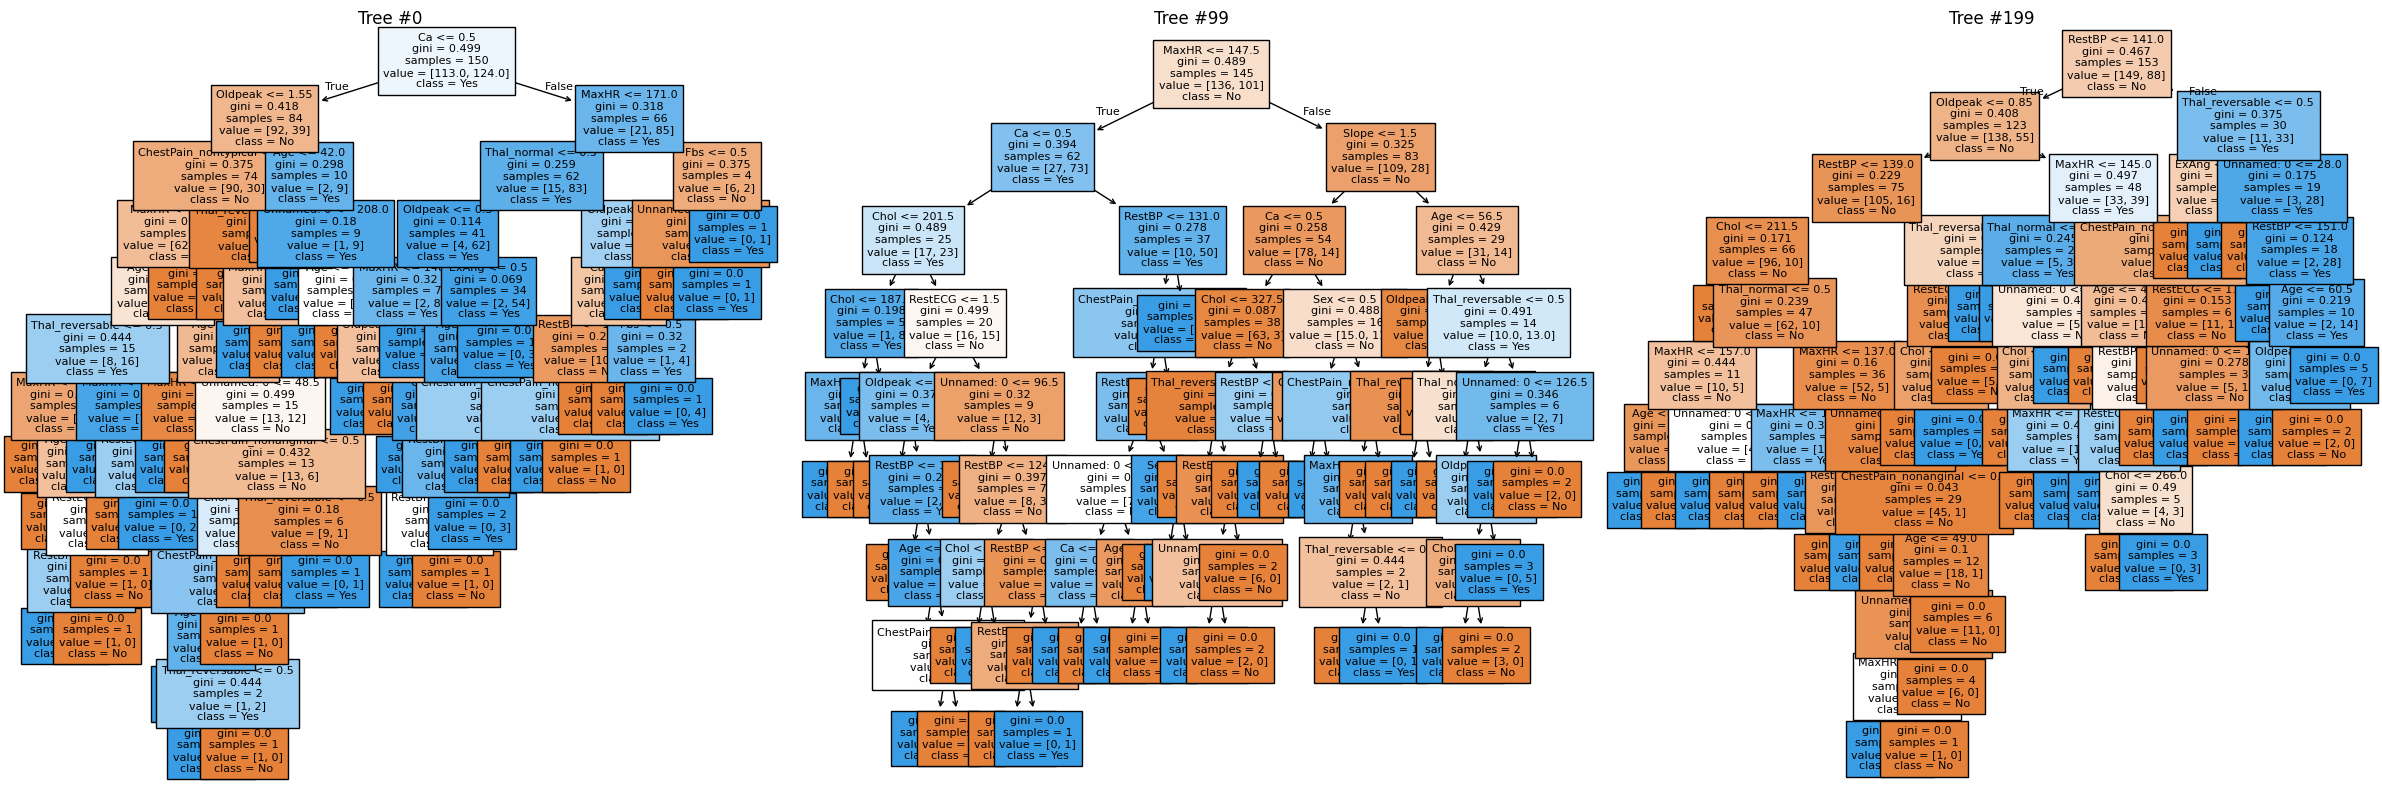

Train accuracy: 1.0
Test accuracy: 0.8


In [18]:
# Grow random trees
Random = RandomForestClassifier(n_estimators = 200)

# Fit trees
Random.fit(X_train,y_train)

# Plot three trees
fig, axes = plt.subplots(1, 3, figsize=(24, 8))

for ax, idx in zip(axes, [0,99,199]):
    plot_tree(
        Random.estimators_[idx],
        filled=True,
        feature_names=X.columns,
        class_names=["No", "Yes"],
        fontsize=8,
        ax=ax,
    )
    ax.set_title(f"Tree #{idx}")

plt.tight_layout()
plt.show()

# Get accuracy
print("Train accuracy:", Random.score(X_train, y_train))
print("Test accuracy:", Random.score(X_test, y_test))

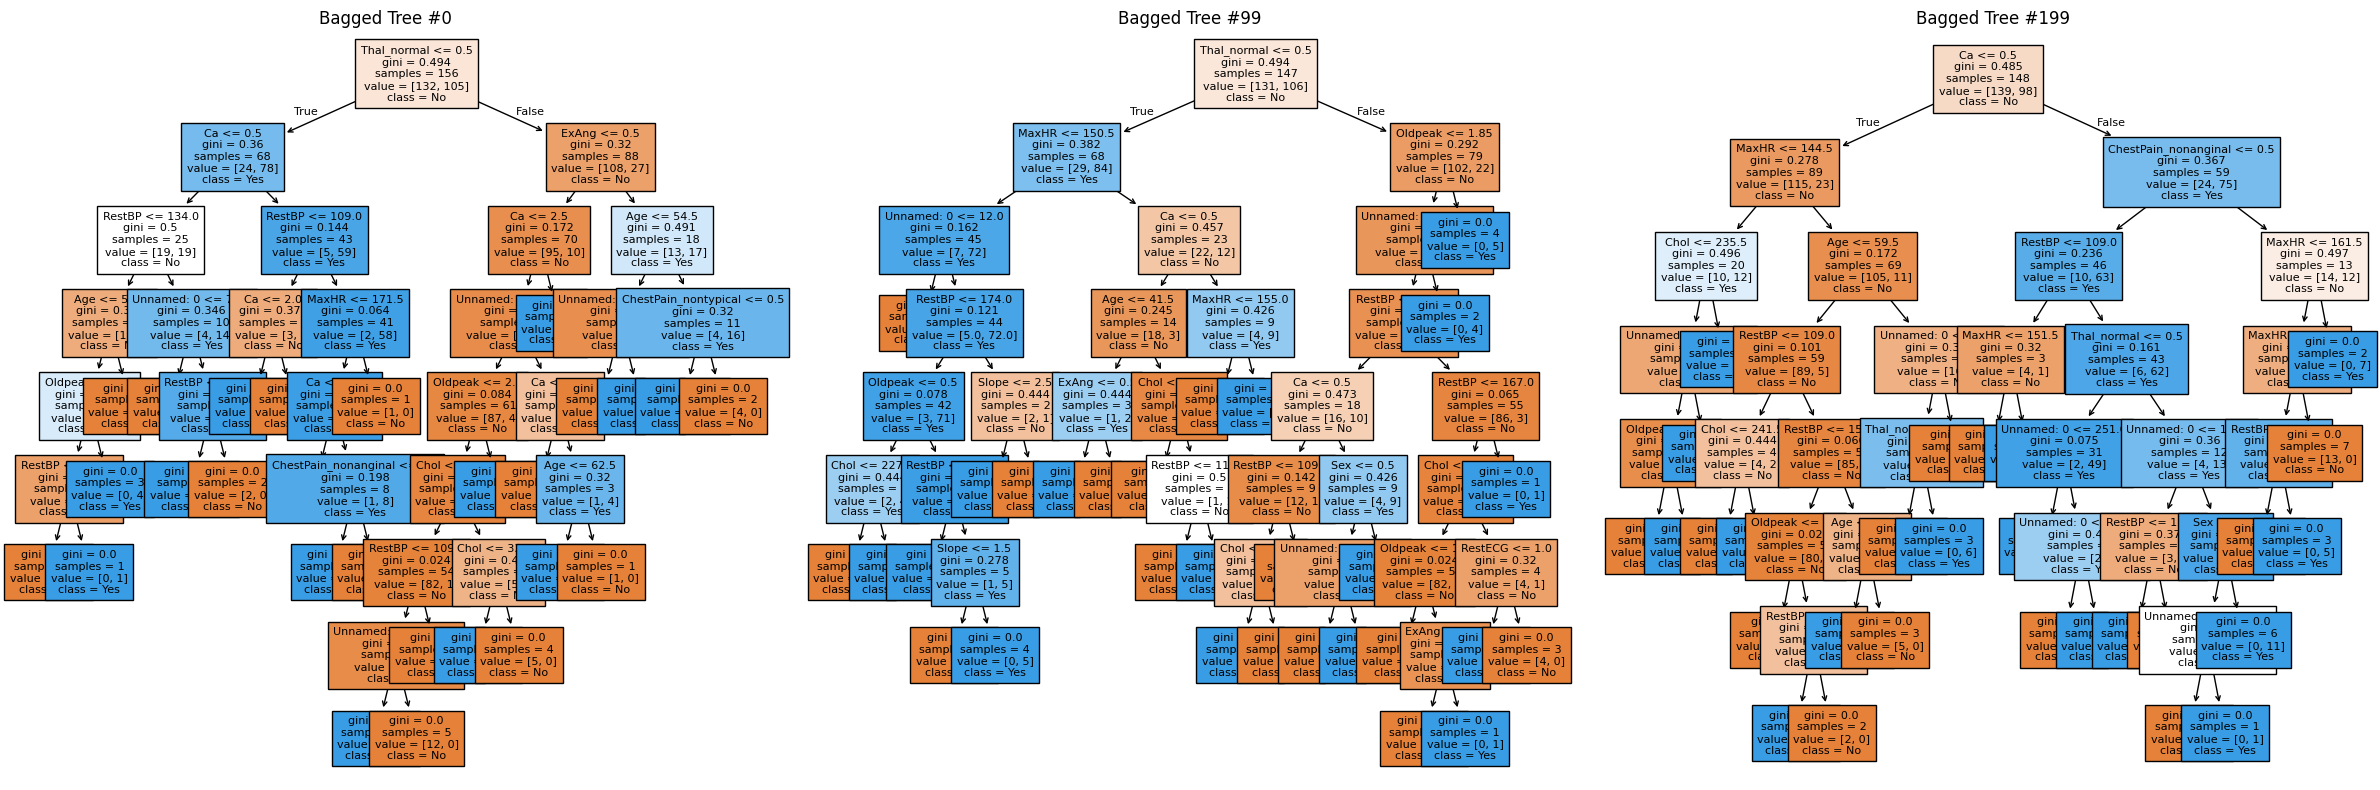

Train accuracy: 1.0
Test accuracy: 0.8333333333333334


In [20]:
# Grow random trees with bagging
BagRandom = RandomForestClassifier(n_estimators = 200, max_features = None)

# Fit trees
BagRandom.fit(X_train,y_train)

# Plot three trees
fig, axes = plt.subplots(1, 3, figsize=(24, 8))

for ax, idx in zip(axes, [0,99,199]):
    plot_tree(
        BagRandom.estimators_[idx],
        filled=True,
        feature_names=X.columns,
        class_names=["No", "Yes"],
        fontsize=8,
        ax=ax,
    )
    ax.set_title(f"Bagged Tree #{idx}")

plt.tight_layout()
plt.show()

# Get accuracy
print("Train accuracy:", BagRandom.score(X_train, y_train))
print("Test accuracy:", BagRandom.score(X_test, y_test))

### 1.2 Tune the Forest

Now tune the hyper-parameters "max_features" and "min_samples_leaf" of the Random Forest classifier to minimize the expected generalization error.

You could use cross-validation. Is there another way to get the desired estimate other than with cross-validation? Use 2000 trees per forest or more.

_Hint:_ `sklearn.model_selection.ParameterGrid` and `<RF_instance>.set_params(...)` might be useful.

_Tip:_ In sklearn, you can set `n_jobs=-1` (or `n_jobs=-2`) in some models and in grid searches to use all (or all but one) of your computer's cores in parallel, which can reduce the running time depending on your computer. Be careful not to "nest" the parallelization.

In [23]:
from sklearn.model_selection import ParameterGrid
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import plot_tree

# Define random forest
Random = RandomForestClassifier(n_estimators = 2000,
                                oob_score=True,
                                random_state=40) # Reproducibility

# Define parametergrid
param_grid = {
    "max_features": ["sqrt", "log2", None],
    "min_samples_leaf": [1, 2, 5, 10, 20]
}


In [24]:
# Evaluate parameter combinations
scores = {}

for params in ParameterGrid(param_grid):
    Random.set_params(**params)
    Random.fit(X_train, y_train)

    scores[str(params)] = Random.oob_score_

# Best parameters and score
best_params = max(scores, key=scores.get)

print("Best parameters:", best_params)
print("Best OOB accuracy:", scores[best_params])

Best parameters: {'max_features': None, 'min_samples_leaf': 5}
Best OOB accuracy: 0.8354430379746836


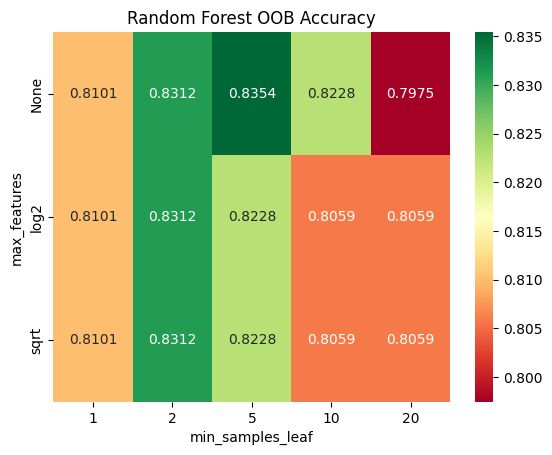

In [26]:
# AI Generated visualisation !
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Convert results dictionary to DataFrame
results_df = pd.DataFrame([
    {"params": eval(params), "OOB_accuracy": score}
    for params, score in scores.items()
])

# Extract hyperparameters
results_df["max_features"] = results_df["params"].apply(lambda x: str(x["max_features"]))
results_df["min_samples_leaf"] = results_df["params"].apply(lambda x: x["min_samples_leaf"])

# Create pivot table
results_pivot = results_df.pivot(
    index="max_features",
    columns="min_samples_leaf",
    values="OOB_accuracy"
)

# Plot heatmap
sns.heatmap(results_pivot, annot=True, fmt=".4f", cmap="RdYlGn")

plt.title("Random Forest OOB Accuracy")
plt.xlabel("min_samples_leaf")
plt.ylabel("max_features")
plt.show()

_Remark:_ When comparing the Random Forest performance with other models, it is better to use cross-validation error estimates, so that the estimates are comparable between models.

### 2.3. Model Diagnostic

We now want to use different metrics to evaluate the model performance on the test set. To do so, consider the best random forest model according to cross-validation score. The first step is to predict the response classes on the test set.

In [30]:
# Grow best Random Forest based on previous results
# Grow random trees
BestRandom = RandomForestClassifier(n_estimators = 2000,
                                    min_samples_leaf=5,
                                    max_features=None,
                                    random_state=40)

# Fit trees
BestRandom.fit(X_train,y_train)

y_pred = BestRandom.predict(X_test)

In [32]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

Compute the confusion matrix using the `confusion_matrix()` function and plot it. You can use the `ConfusionMatrixDisplay` helper, or create the plot yourself. Comment the results.

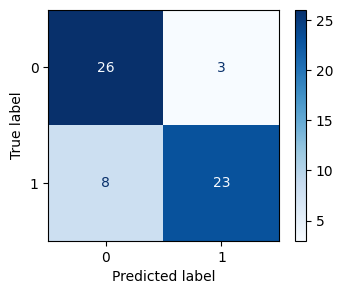

In [ ]:
# Display confusion matrix
dispconf = ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=BestRandom.classes_)

plt.figure(figsize=(4, 3))
dispconf.plot(cmap=plt.cm.Blues, ax=plt.gca())

Perform a classification report using the `classification_report()` function, and comment the results.

In [ ]:
print(classification_report(y_test, y_pred)) 

# 0.82 accuracy, more likely to predict 1 than 0

              precision    recall  f1-score   support

           0       0.76      0.90      0.83        29
           1       0.88      0.74      0.81        31

    accuracy                           0.82        60
   macro avg       0.82      0.82      0.82        60
weighted avg       0.83      0.82      0.82        60



Plot the [Receiver Operating Characteristic (ROC)](https://en.wikipedia.org/wiki/Receiver_operating_characteristic) and estimate its Area Under Curve (AUC) using `roc_curve` and `roc_auc_score`. See e.g. `RocCurveDisplay` or `RocCurveDisplay.from_estimator` for plot helpers. Comment the results.

In [44]:
from sklearn.metrics import roc_auc_score, roc_curve, RocCurveDisplay

ROC AUC Score: 0.889


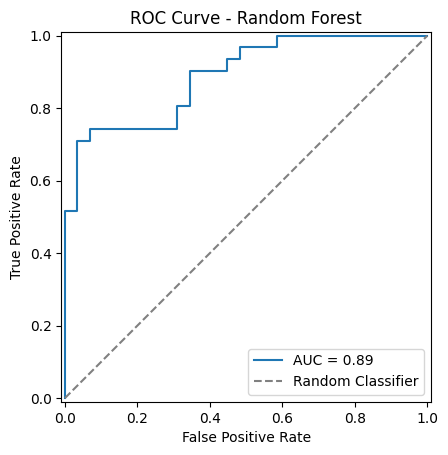

In [48]:
roc_auc = roc_auc_score(y_test, BestRandom.predict_proba(X_test)[:, 1])
fpr, tpr, thresholds = roc_curve(y_test, BestRandom.predict_proba(X_test)[:, 1])

print(f"ROC AUC Score: {roc_auc:.3f}")

# Plot using the fpr, tpr, and roc_auc you already calculated
disp = RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc)
disp.plot()

# Add a diagonal dashed line representing random guessing (AUC = 0.5)
plt.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Random Classifier")
plt.title("ROC Curve - Random Forest")
plt.legend()
plt.show()


One can also have a look at the `yellowbrick` package for more pre-coded diagnostic plots (with `pip install yellowbrick` (https://www.scikit-yb.org/en/latest/)).

## 3. Theoretical Exercise: Properties of Bootstrap

We will now derive the probability that a given observation is part
of a bootstrap sample. 

Let $Z = \{Z_1, \dots, Z_n\}$ be our original sample of size $n$. (For example, $Z_i = (X_i, Y_i)$
can represent the pair of predictors and target variables for each observation $i = 1, \dots, n$.)

Let $Z^* = \{Z_1^*, \dots, Z_n^*\}$ be a bootstrap sample of size $n$, resampled from $Z$. (You can think of it as one of the $B$ bootstrap samples $Z^{*1},\ldots,Z^{*B}$ used for bagging.)

We want to show that, for each $i = 1, \dots, n$, the probability that $Z_i$ is part of the bootstrap sample is $P\left(Z_i \in Z^*\right) = 1 - 1/e$.

* What is the probability that the first bootstrap observation
is not the $i$-th observation from the original sample? 
Justify your answer.

* What is the probability that the second bootstrap observation
is not the $i$-th observation from the original sample?

* Argue that the probability that the $i$-th observation is not in the
bootstrap sample is $(1 - \frac{1}{n})^n$.

* When $n = 5$, what is the probability that the $i$-th observation is
in the bootstrap sample?

* When $n = 100$, what is the probability that the $i$-th observation
is in the bootstrap sample?

* When $n \to \infty$, what is the probability that the $i$-th observation
is in the bootstrap sample?